# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Raihan Nurhakim | 5054251030 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.
df = pd.read_csv('Mall_Customers.csv')
print(df.head())
print('Shape:', df.shape)
print(df.dtypes)
print(df.describe())
print('Missing value:')
print(df.isnull().sum())
print('Jumlah baris duplikat:', df.duplicated().sum())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Shape: (200, 5)
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750

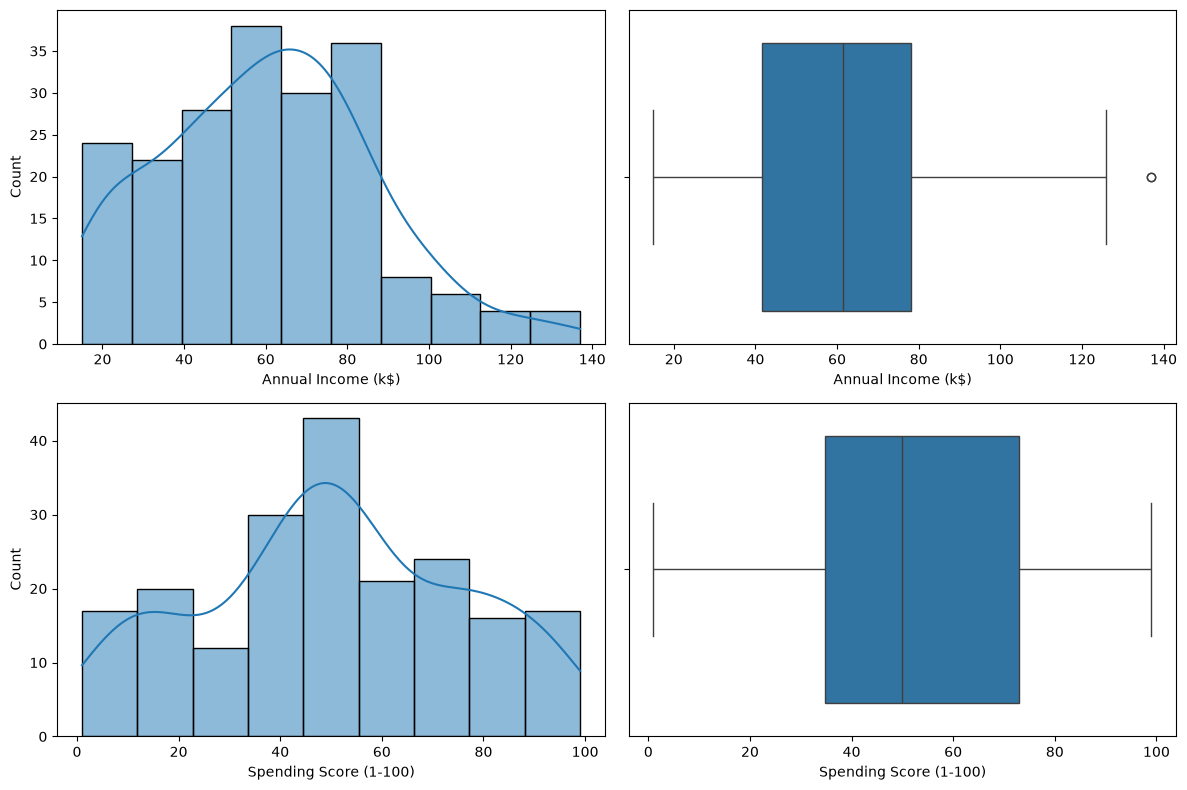

In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[0, 0])
sns.boxplot(x=df['Annual Income (k$)'], ax=axes[0, 1])
sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[1, 0])
sns.boxplot(x=df['Spending Score (1-100)'], ax=axes[1, 1])
plt.tight_layout()
plt.show()

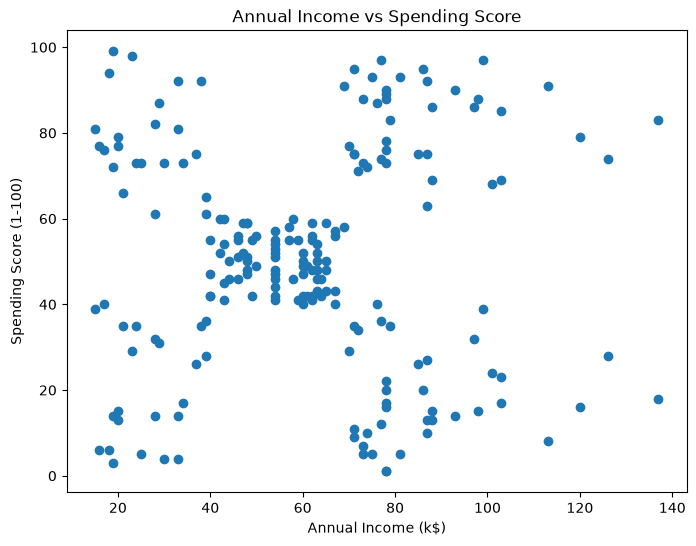

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.
plt.figure(figsize=(8, 6))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score')
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?


- Dataset terdiri dari 200 pelanggan. Tidak ditemukan missing value maupun baris duplikat, sehingga tidak ada baris yang perlu dihapus karena dua masalah tersebut.
- Annual Income berada pada rentang 15-137 k$, sedangkan Spending Score berada pada rentang 1-99. Kedua fitur memiliki rentang dan sebaran yang berbeda. Dari histogram dan boxplot, nilai Annual Income lebih banyak terkumpul pada rentang menengah, tetapi terdapat beberapa nilai yang jauh lebih tinggi. Spending Score tersebar pada rentang yang cukup lebar.
- Scatter plot menunjukkan beberapa kelompok pelanggan yang relatif terlihat, terutama kelompok dengan pendapatan dan spending score rendah/tinggi. Namun, batas antarkelompok tidak semuanya terpisah secara tegas.

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.
df = df.dropna().drop_duplicates()
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()
print(X.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
print(X_scaled.head())

   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980


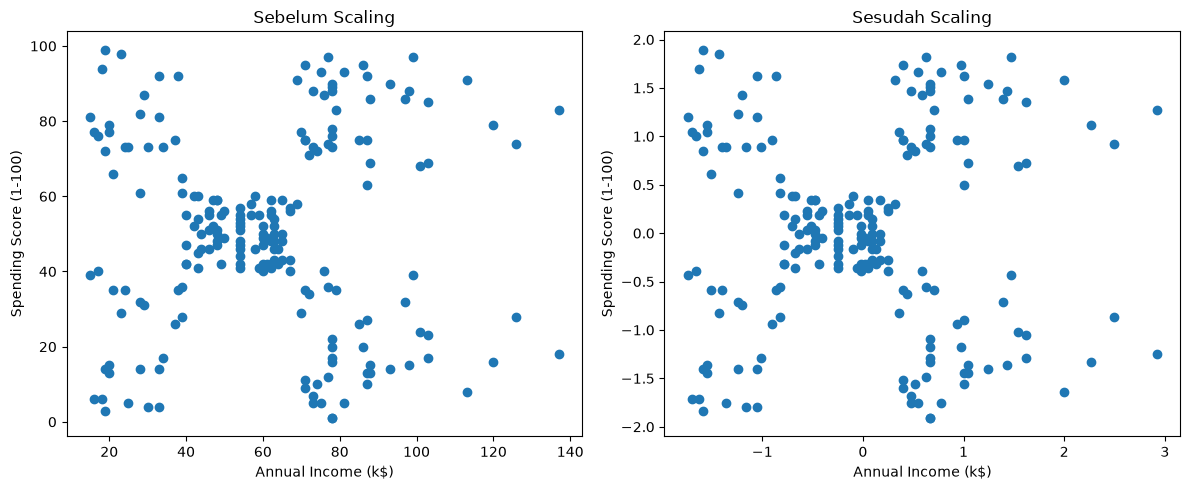

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'])
axes[0].set_title('Sebelum Scaling')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[1].scatter(X_scaled['Annual Income (k$)'], X_scaled['Spending Score (1-100)'])
axes[1].set_title('Sesudah Scaling')
axes[1].set_xlabel('Annual Income (k$)')
axes[1].set_ylabel('Spending Score (1-100)')
plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

Kedua fitur dipilih karena berupa data numerik dan dapat menggambarkan pelanggan dari sisi kemampuan ekonomi serta perilaku belanjanya. Keduanya juga dapat divisualisasikan dalam scatter plot dua dimensi sehingga pola kelompok lebih mudah diamati. CustomerID tidak digunakan karena hanya berfungsi sebagai identitas unik pelanggan. Nilainya tidak menunjukkan kemiripan atau perbedaan karakteristik pelanggan, sehingga jika dimasukkan justru dapat memengaruhi jarak secara tidak bermakna.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [ ]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).
print(pd.Series(labels_dbscan).value_counts().sort_index())
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = list(labels_dbscan).count(-1)
print('Jumlah cluster:', n_clusters_dbscan)
print('Jumlah noise:', n_noise_dbscan)

-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64
Jumlah cluster: 7
Jumlah noise: 35


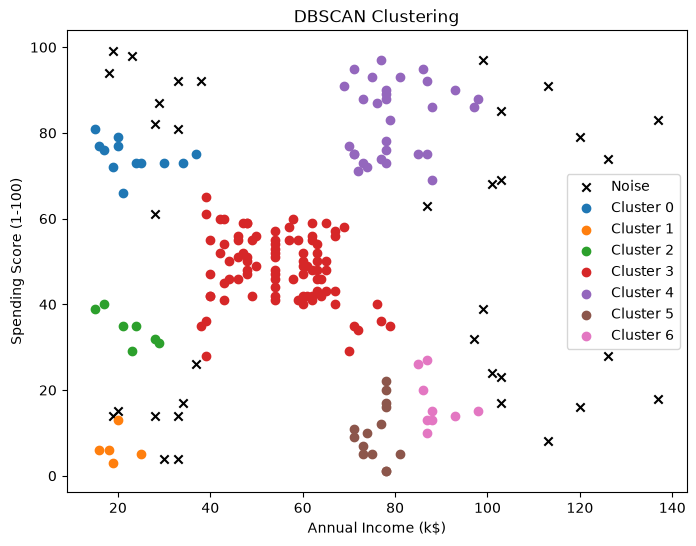

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.
plt.figure(figsize=(8, 6))
for label in sorted(set(labels_dbscan)):
    mask = labels_dbscan == label
    if label == -1:
        plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], c='black', marker='x', label='Noise')
    else:
        plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], label=f'Cluster {label}')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('DBSCAN Clustering')
plt.legend()
plt.show()

In [11]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.
results = []
for eps in [0.2, 0.3, 0.4, 0.5]:
    for min_samples in [3, 5, 7]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        if n_clusters >= 2 and n_clusters < len(labels):
            sil = silhouette_score(X_scaled, labels)
        else:
            sil = np.nan
        results.append([eps, min_samples, n_clusters, n_noise, sil])
results_dbscan = pd.DataFrame(results, columns=['eps', 'min_samples', 'n_clusters', 'n_noise', 'silhouette'])
print(results_dbscan)

    eps  min_samples  n_clusters  n_noise  silhouette
0   0.2            3          13       44    0.230585
1   0.2            5           7       77    0.140579
2   0.2            7           4      100    0.055593
3   0.3            3           9       14    0.413619
4   0.3            5           7       35    0.316141
5   0.3            7           4       72    0.231465
6   0.4            3           4       10    0.362691
7   0.4            5           4       15    0.413258
8   0.4            7           4       20    0.404304
9   0.5            3           2        7    0.356602
10  0.5            5           2        8    0.350446
11  0.5            7           2       12    0.352615


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?


- Ketika eps diperbesar, radius pencarian tetangga menjadi lebih luas. Titik yang sebelumnya terpisah atau dianggap noise dapat terhubung ke suatu kelompok, sehingga jumlah cluster cenderung berkurang dan noise juga berkurang. Hal ini terlihat pada min_samples=5: pada eps=0.2 terbentuk 7 cluster dengan 77 noise, sedangkan pada eps=0.5 terbentuk 2 cluster dengan 8 noise. Jika terlalu besar, beberapa kelompok berbeda dapat tergabung.
- Ketika min_samples diperbesar, syarat jumlah tetangga untuk membentuk core point menjadi lebih ketat. Akibatnya, jumlah cluster cenderung berkurang dan jumlah noise meningkat. Contohnya pada eps=0.2, noise bertambah dari 44 (min_samples=3) menjadi 100 (min_samples=7).
- Kombinasi parameter menghasilkan jumlah cluster dan noise yang berbeda. Pada percobaan ini, eps=0.2 dengan min_samples=7 menghasilkan 4 cluster dan 100 noise, sehingga terlalu banyak titik tidak terkelompokkan. Sementara itu, eps=0.5 menghasilkan 2 cluster dan hanya 7-12 noise, tetapi kelompok yang berbeda berisiko tergabung. Kombinasi eps=0.3-0.4 memberi hasil yang lebih seimbang. Model DBSCAN yang digunakan pada visualisasi dan evaluasi utama adalah eps=0.3 dan min_samples=5, yang menghasilkan 7 cluster dan 35 noise.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
print(pd.Series(labels_birch).value_counts().sort_index())
print('Jumlah cluster:', len(set(labels_birch)))

0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64
Jumlah cluster: 5


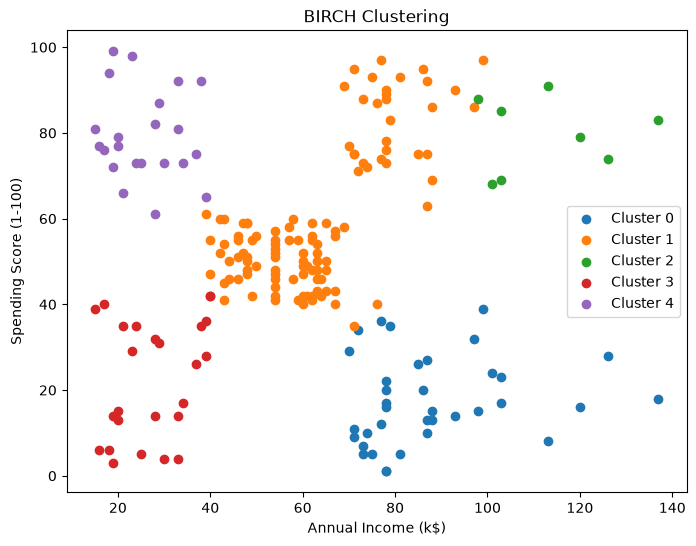

In [14]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.
plt.figure(figsize=(8, 6))
for label in sorted(set(labels_birch)):
    mask = labels_birch == label
    plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], label=f'Cluster {label}')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('BIRCH Clustering')
plt.legend()
plt.show()

In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.
results = []
for threshold in [0.3, 0.5, 0.7, 1.0]:
    labels = Birch(threshold=threshold, n_clusters=5).fit_predict(X_scaled)
    n_clusters = len(set(labels))
    if n_clusters >= 2:
        sil = silhouette_score(X_scaled, labels)
    else:
        sil = np.nan
    results.append([threshold, n_clusters, sil])
results_birch = pd.DataFrame(results, columns=['threshold', 'n_clusters', 'silhouette'])
print(results_birch)

   threshold  n_clusters  silhouette
0        0.3           5    0.478062
1        0.5           5    0.414450
2        0.7           5    0.420676
3        1.0           4    0.388557


c:\Users\Raihan\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

- Secara umum, threshold yang lebih besar membuat titik-titik lebih mudah digabungkan ke dalam subcluster, sehingga jumlah subcluster awal cenderung berkurang. Pada percobaan dengan n_clusters=5, jumlah cluster akhir tetap 5 untuk threshold 0.3, 0.5, dan 0.7. Pada threshold 1.0 hanya ditemukan 4 subcluster, sehingga BIRCH menghasilkan 4 cluster dan memberikan peringatan bahwa jumlah subcluster yang ditemukan kurang dari 5.
- BIRCH tidak memberikan label noise secara eksplisit. Titik yang jauh dari kelompok utama tetap dimasukkan ke cluster terdekat. Berbeda dengan DBSCAN, titik yang tidak memenuhi kepadatan minimum dapat diberi label -1 sebagai noise.
- n_clusters mengatur jumlah cluster akhir yang diinginkan. Jika nilainya ditentukan, BIRCH berusaha menggabungkan subcluster menjadi jumlah tersebut. Namun, hasil eksperimen threshold 1.0 menunjukkan bahwa jumlah akhir dapat kurang dari nilai yang diminta apabila subcluster yang terbentuk tidak mencukupi.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.
gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)

In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.
print(pd.Series(labels_gmm).value_counts().sort_index())
proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f'Cluster {i}' for i in range(gmm.n_components)])
print(proba_df.head())
print('Titik dengan probabilitas maksimum < 0.6:', (proba.max(axis=1) < 0.6).sum())

0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64
      Cluster 0     Cluster 1     Cluster 2     Cluster 3  Cluster 4
0  1.576897e-05  1.880092e-08  9.520312e-04  5.200131e-08   0.999032
1  1.627762e-05  1.895968e-04  9.997902e-01  4.210134e-23   0.000004
2  2.213394e-19  9.526157e-19  1.225495e-12  1.862233e-04   0.999814
3  1.054448e-04  1.800877e-04  9.996937e-01  3.793901e-21   0.000021
4  6.473014e-05  3.842732e-08  1.556695e-03  4.757227e-08   0.998378
Titik dengan probabilitas maksimum < 0.6: 1


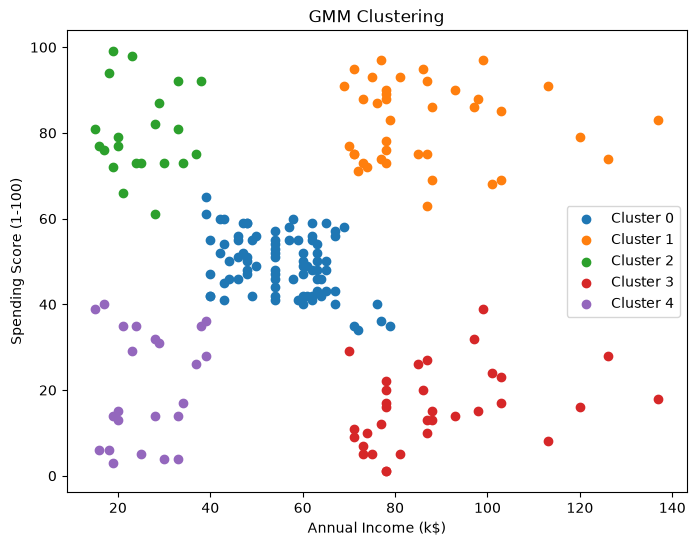

In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.
plt.figure(figsize=(8, 6))
for label in sorted(set(labels_gmm)):
    mask = labels_gmm == label
    plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], label=f'Cluster {label}')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('GMM Clustering')
plt.legend()
plt.show()

In [19]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.
results = []
for n in range(2, 9):
    model = GaussianMixture(n_components=n, covariance_type='full', random_state=42)
    labels = model.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    results.append([n, sil, model.bic(X_scaled)])
results_gmm = pd.DataFrame(results, columns=['n_components', 'silhouette', 'bic'])
print(results_gmm)

   n_components  silhouette          bic
0             2    0.379082  1153.904655
1             3    0.430190  1151.718274
2             4    0.413392  1103.790149
3             5    0.553689  1058.652252
4             6    0.516982  1074.682807
5             7    0.509057  1087.328517
6             8    0.430210  1102.370701


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

- Probabilitas keanggotaan GMM menunjukkan tingkat keanggotaan suatu pelanggan pada masing-masing komponen Gaussian. Satu pelanggan dapat memiliki probabilitas pada beberapa komponen sekaligus. Label akhir ditentukan dari komponen dengan probabilitas terbesar. Pada hasil ini, hanya ada 1 pelanggan yang probabilitas maksimumnya di bawah 0,6, sehingga sebagian besar pelanggan memiliki keanggotaan yang cukup jelas.
- Perubahan n_components mengubah jumlah distribusi Gaussian yang digunakan untuk memodelkan data. Pada percobaan ini, nilai 5 menghasilkan Silhouette Score tertinggi, yaitu 0,5537, dan BIC terendah, yaitu 1058,65. Nilai tersebut lebih baik daripada percobaan dengan 2-4 maupun 6-8 komponen berdasarkan kedua kriteria yang diuji.
- Jumlah komponen perlu ditentukan sebelum model dilatih karena GMM mengestimasi parameter untuk sejumlah komponen yang sudah ditetapkan. EM memperbarui parameter dan probabilitas keanggotaan secara iteratif, tetapi tidak menentukan sendiri jumlah komponen yang akan digunakan.
- Pada eksperimen ini, model dengan Silhouette Score tertinggi juga memiliki BIC terendah, yaitu GMM dengan 5 komponen. Keduanya kebetulan memilih model yang sama pada dataset ini, tetapi maknanya berbeda: Silhouette menilai pemisahan dan kekompakan cluster, sedangkan BIC mempertimbangkan kecocokan model sekaligus kompleksitasnya.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.
def evaluate(X_data, labels):
    labels = np.asarray(labels)
    mask = labels != -1
    X_eval = np.asarray(X_data)[mask]
    labels_eval = labels[mask]
    n_clusters = len(set(labels_eval))
    if n_clusters < 2 or n_clusters >= len(labels_eval):
        return n_clusters, np.nan, np.nan, np.nan
    sil = silhouette_score(X_eval, labels_eval)
    db = davies_bouldin_score(X_eval, labels_eval)
    ch = calinski_harabasz_score(X_eval, labels_eval)
    return n_clusters, sil, db, ch

In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.
rows = []
for name, labels in [('DBSCAN', labels_dbscan), ('BIRCH', labels_birch), ('GMM', labels_gmm)]:
    n_clusters, sil, db, ch = evaluate(X_scaled, labels)
    n_noise = list(labels).count(-1) if name == 'DBSCAN' else 0
    rows.append([name, n_clusters, n_noise, sil, db, ch])
comparison = pd.DataFrame(rows, columns=['model', 'n_clusters', 'n_noise', 'silhouette', 'davies_bouldin', 'calinski_harabasz'])
print(comparison)

    model  n_clusters  n_noise  silhouette  davies_bouldin  calinski_harabasz
0  DBSCAN           7       35    0.524328        0.579955         185.575811
1   BIRCH           5        0    0.414450        0.697938         125.948605
2     GMM           5        0    0.553689        0.576010         244.940197


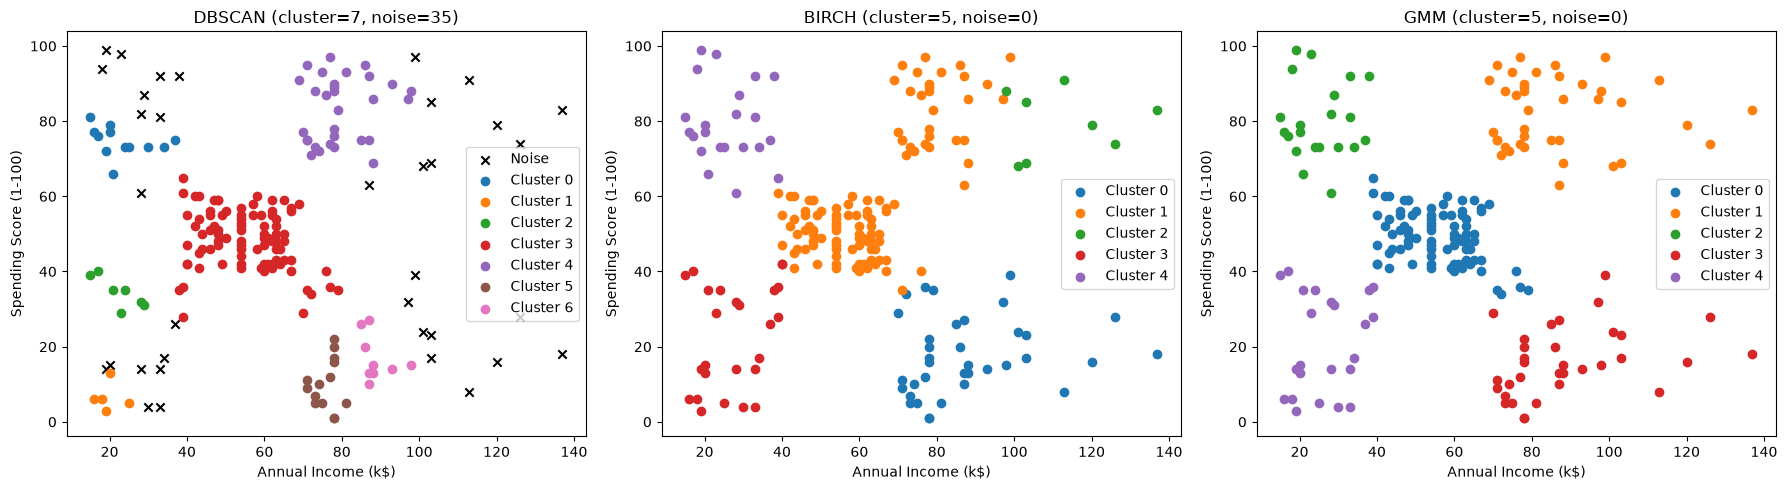

In [22]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, labels) in zip(axes, [('DBSCAN', labels_dbscan), ('BIRCH', labels_birch), ('GMM', labels_gmm)]):
    for label in sorted(set(labels)):
        mask = labels == label
        if label == -1:
            ax.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], c='black', marker='x', label='Noise')
        else:
            ax.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], label=f'Cluster {label}')
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    ax.set_title(f'{name} (cluster={n_clusters}, noise={n_noise})')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')
    ax.legend()
plt.tight_layout()
plt.show()

In [23]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.
for name, labels in [('DBSCAN', labels_dbscan), ('BIRCH', labels_birch), ('GMM', labels_gmm)]:
    print(f'\n=== {name} ===')
    profile = X.copy()
    profile['cluster'] = labels
    print(profile.groupby('cluster')[['Annual Income (k$)', 'Spending Score (1-100)']].agg(['count', 'mean', 'median']))


=== DBSCAN ===
        Annual Income (k$)                   Spending Score (1-100)  \
                     count       mean median                  count   
cluster                                                               
-1                      35  70.600000   87.0                     35   
 0                      12  23.166667   20.5                     12   
 1                       5  19.600000   19.0                      5   
 2                       7  22.428571   23.0                      7   
 3                      88  55.227273   54.0                     88   
 4                      30  79.533333   78.0                     30   
 5                      14  75.928571   77.5                     14   
 6                       9  88.777778   87.0                      9   

                           
              mean median  
cluster                    
-1       51.657143   61.0  
 0       74.583333   74.0  
 1        6.600000    6.0  
 2       34.428571   35.0  
 3    

### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Ya (opsional; bisa lewat `n_clusters` atau threshold) | Ya (`n_components`) |
| Dapat memberi label noise secara eksplisit? | Ya (label -1) | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | `eps` dan `min_samples` | `threshold` dan `n_clusters` | `n_components` dan `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bebas/berbasis kepadatan | Sferis (bola) berdasarkan radius subcluster | Elips/Gaussian sesuai matriks kovarians |
| Kelebihan | Tidak perlu jumlah cluster; mendeteksi noise; bentuk cluster bebas | Efisien untuk data besar; tidak perlu jumlah cluster jika memakai threshold | Model probabilistik; cluster berbentuk elips; memberi derajat keanggotaan |
| Kekurangan | Sensitif terhadap eps dan min_samples; sulit jika kepadatan berbeda | Sensitif terhadap threshold; hasil bergantung urutan data | Harus menentukan n_components; asumsi Gaussian |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?


Scaling diperlukan karena Annual Income dan Spending Score memiliki rentang nilai yang berbeda. Jika data tidak distandardisasi, fitur dengan rentang atau variasi lebih besar dapat lebih mendominasi perhitungan jarak. StandardScaler mengubah kedua fitur ke skala yang sebanding sehingga kontribusinya dalam proses clustering lebih seimbang.

Pada DBSCAN, eps menentukan radius tetangga dan min_samples menentukan jumlah minimum tetangga untuk membentuk titik inti. Hasil percobaan menunjukkan bahwa ketika eps diperbesar, cluster cenderung bergabung dan noise berkurang. Sebaliknya, ketika min_samples diperbesar, syarat pembentukan cluster menjadi lebih ketat dan noise cenderung bertambah. Konfigurasi utama eps=0.3 dan min_samples=5 menghasilkan 7 cluster dan 35 titik noise. Nilai ini masih menyisakan cukup banyak noise, sehingga hasil DBSCAN perlu dibaca bersama visualisasi dan profil cluster.

Pada BIRCH, threshold mengatur seberapa dekat titik harus berada agar dapat dirangkum dalam subcluster. Threshold yang lebih besar cenderung menghasilkan subcluster yang lebih sedikit. n_clusters menentukan jumlah cluster akhir yang diinginkan. Pada eksperimen ini, threshold 0.3, 0.5, dan 0.7 menghasilkan 5 cluster akhir karena n_clusters=5 ditetapkan, sedangkan threshold 1.0 hanya menghasilkan 4 cluster karena subcluster yang tersedia tidak mencukupi.

GMM memberikan probabilitas keanggotaan setiap pelanggan pada masing-masing komponen Gaussian. Dalam algoritma EM, probabilitas tersebut digunakan pada tahap Expectation, kemudian parameter distribusi diperbarui pada tahap Maximization. Proses ini dilakukan berulang sampai model konvergen. Pada pengujian n_components 2 sampai 8, 5 komponen memberikan Silhouette Score tertinggi (0,5537) sekaligus BIC terendah (1058,65).

Dilihat dari hasil evaluasi, GMM merupakan algoritma dengan performa terbaik pada konfigurasi yang diuji. GMM memiliki Silhouette Score tertinggi sebesar 0,5537, Davies-Bouldin terendah sebesar 0,5760, dan Calinski-Harabasz tertinggi sebesar 244,94. Hasil ini menunjukkan bahwa cluster GMM memiliki kekompakan dan pemisahan yang lebih baik dibandingkan DBSCAN dan BIRCH. GMM juga membagi data menjadi lima kelompok tanpa menandai pelanggan sebagai noise. DBSCAN tetap berguna untuk menemukan titik yang berada di luar area padat, tetapi pada konfigurasi utama terdapat 35 titik noise. Sementara itu, BIRCH menghasilkan lima cluster dengan nilai metrik evaluasi yang lebih rendah. Meskipun demikian, hasil ini tidak berarti GMM selalu menjadi algoritma terbaik untuk semua dataset karena performa clustering dipengaruhi oleh karakteristik data dan parameter yang digunakan.

Pada dataset ini, GMM merupakan model yang paling mudah diinterpretasikan dari hasil segmentasi yang diperoleh. Hal ini karena lima cluster yang terbentuk memiliki karakteristik pendapatan dan spending score yang cukup jelas, mulai dari kelompok pendapatan dan pengeluaran rendah hingga kelompok pendapatan dan pengeluaran tinggi. Dengan begitu, setiap cluster dapat diberi nama berdasarkan karakteristik pelanggannya. Meskipun DBSCAN juga mudah dipahami karena dapat menunjukkan titik noise, hasil segmentasi GMM lebih mudah dijelaskan berdasarkan profil median setiap cluster.

Profil median GMM membantu menjelaskan lima kelompok yang terbentuk:
- Cluster 0 (84 pelanggan): median pendapatan 55,5 k$ dan spending score 49,5, sehingga dapat disebut kelompok pendapatan dan pengeluaran menengah.
- Cluster 1 (39 pelanggan): median pendapatan 79 k$ dan spending score 83, sehingga merupakan kelompok pendapatan tinggi dan pengeluaran tinggi.
- Cluster 2 (21 pelanggan): median pendapatan 24 k$ dan spending score 77, sehingga merupakan kelompok pendapatan rendah dan pengeluaran tinggi.
- Cluster 3 (33 pelanggan): median pendapatan 88 k$ dan spending score 15, sehingga merupakan kelompok pendapatan tinggi dan pengeluaran rendah.
- Cluster 4 (23 pelanggan): median pendapatan 25 k$ dan spending score 17, sehingga merupakan kelompok pendapatan rendah dan pengeluaran rendah.

Penggunaan dua fitur membuat visualisasi dan interpretasi lebih sederhana, tetapi belum menggambarkan keseluruhan karakteristik pelanggan. Faktor seperti usia dan gender belum dipertimbangkan sebagai fitur dalam clustering. Selain itu, dataset hanya berisi 200 pelanggan, sehingga pola yang ditemukan belum tentu mewakili populasi pelanggan yang lebih luas.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

Kesimpulan:
1. Ketiga algoritma dapat mengelompokkan pelanggan berdasarkan Annual Income dan Spending Score, tetapi hasilnya berbeda karena masing-masing menggunakan pendekatan yang berbeda. DBSCAN membentuk kelompok berdasarkan kepadatan dan dapat menandai noise, BIRCH merangkum data menjadi subcluster, sedangkan GMM memodelkan data sebagai campuran distribusi Gaussian.
2. Pada konfigurasi yang dibandingkan, GMM memberikan hasil paling baik. Model dengan n_components=5 dan covariance_type='full' memperoleh Silhouette Score 0,5537, Davies-Bouldin 0,5760, dan Calinski-Harabasz 244,94. Selain itu, BIC terendah juga diperoleh pada 5 komponen, yaitu 1058,65.
3. Parameter DBSCAN yang digunakan pada evaluasi utama adalah eps=0.3 dan min_samples=5; konfigurasi ini menghasilkan 7 cluster dan 35 noise. BIRCH menggunakan threshold=0.5 dan n_clusters=5, menghasilkan 5 cluster. GMM menggunakan 5 komponen dengan kovarians full. Pemilihan GMM didukung oleh hasil metrik evaluasi dan BIC pada percobaan ini.
4. Lima cluster GMM menunjukkan kelompok pelanggan dengan karakteristik pendapatan dan pengeluaran yang berbeda, yaitu menengah-menengah, tinggi-tinggi, rendah-tinggi, tinggi-rendah, dan rendah-rendah.

Saran:
- Pada eksperimen selanjutnya, fitur usia atau gender dapat dianalisis sebagai informasi tambahan untuk melihat apakah segmentasi pelanggan menjadi lebih informatif. Jika digunakan sebagai fitur, pengolahan fitur kategorikal perlu dilakukan dengan tepat.
- Parameter DBSCAN, BIRCH, dan GMM dapat diuji kembali dengan kombinasi yang lebih beragam. Untuk DBSCAN, pemilihan eps dapat dibantu dengan k-distance plot; untuk GMM, jumlah komponen dapat dibandingkan menggunakan BIC dan metrik clustering.
- Dataset yang lebih besar dan lebih beragam dapat digunakan agar hasil segmentasi lebih mewakili karakteristik pelanggan secara umum.